=== HASIL EVALUASI MODEL RANDOM FOREST ===
Akurasi Model : 80.62%

Classification Report:
                 precision    recall  f1-score   support

Jelek/Biasa (0)       0.78      0.82      0.80       149
      Bagus (1)       0.83      0.80      0.81       171

       accuracy                           0.81       320
      macro avg       0.81      0.81      0.81       320
   weighted avg       0.81      0.81      0.81       320



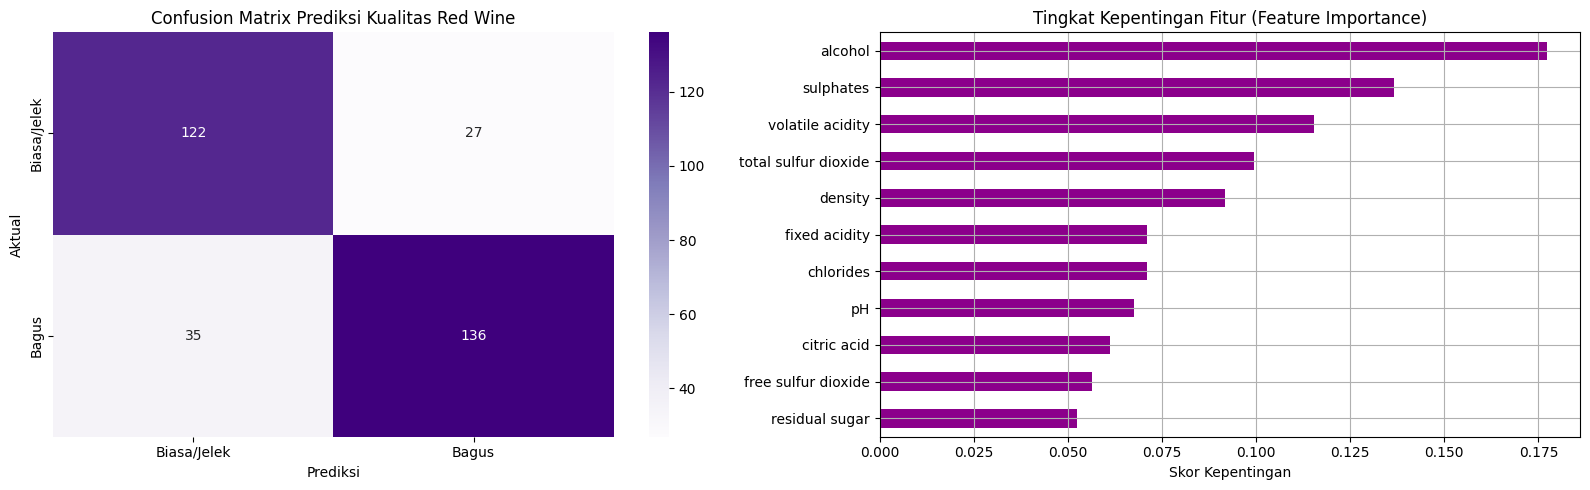

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')

# 2. PEMBERSIHAN DATA & PREPROCESSING
# A. Cek & tangani missing values
df = df.dropna()

# B. Ubah target 'quality' menjadi binary:
# Nilai quality >= 6 dianggap 'Bagus' (1), < 6 dianggap 'Biasa/Jelek' (0)
df['quality_label'] = df['quality'].apply(lambda x: 1 if x >= 6 else 0)

# C. Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

# D. Train-Test Split (80:20)
# Random Forest TIDAK memerlukan StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. TRAINING MODEL RANDOM FOREST
# n_estimators=100 membuat ensemble berisi 100 pohon keputusan
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL RANDOM FOREST ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Jelek/Biasa (0)', 'Bagus (1)']))

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visualisasi 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    ax=axes[0],
    xticklabels=['Biasa/Jelek', 'Bagus'],
    yticklabels=['Biasa/Jelek', 'Bagus']
)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix Prediksi Kualitas Red Wine")

# Visualisasi 2: Feature Importance (Fitur mana yang paling menentukan kualitas)
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='darkmagenta')
axes[1].set_title("Tingkat Kepentingan Fitur (Feature Importance)")
axes[1].set_xlabel("Skor Kepentingan")
axes[1].grid(True)

plt.tight_layout()
plt.show()